# Partie 5 : Construction et évaluation du modèle prédictif

**Cours :** 030513 IFM, Intelligence artificielle appliquée au prétraitement des données (automne 2026)

**Évaluation sommative 2 :** Création des pipelines (Prof. Nadjate Saïdani)

**Équipe :**
- Akiella Wankoua, Blonde Béatrice
- Essomba, Martin Junior
- Gouater, Rene Eutyche
- Misse, Anthony

**But du notebook :** choisir un algorithme de classification, construire le pipeline complet (prétraitement + sélection + modèle), l'entraîner et l'évaluer sur le test.

**Ce que le notebook utilise :**
- `donnees/preparees/` (notebook 01)
- `modeles/etape4_pipeline_selection.joblib` : prétraitement + sélection (notebook 04)
- `notebooks/transformateurs.py` : nos classes (notebook 03)

**Ce que le notebook produit pour la suite :**
- `figures/05_matrice_confusion.png` (pour les diapositives)

## Importation des librairies

In [1]:
from pathlib import Path

import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

# Nos classes : nécessaires pour recharger le pipeline du notebook 04
from transformateurs import CreationVariables, PlafonnementValeurs

DOSSIER_PREPAREES = Path("../donnees/preparees")
DOSSIER_MODELES = Path("../modeles")
DOSSIER_FIGURES = Path("../figures")

## Chargement des résultats des notebooks 01 et 04

In [2]:
X_train = pd.read_csv(DOSSIER_PREPAREES / "X_train.csv", dtype={"agent": str})
X_test = pd.read_csv(DOSSIER_PREPAREES / "X_test.csv", dtype={"agent": str})
y_train = pd.read_csv(DOSSIER_PREPAREES / "y_train.csv")["is_canceled"]
y_test = pd.read_csv(DOSSIER_PREPAREES / "y_test.csv")["is_canceled"]

pipeline_selection = joblib.load(DOSSIER_MODELES / "etape4_pipeline_selection.joblib")

print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Étapes récupérées du notebook 04 :", list(pipeline_selection.named_steps))
print("Taux d'annulation dans le train :", round(y_train.mean() * 100, 1), "%")

X_train : (69783, 27) | X_test : (17446, 27)
Étapes récupérées du notebook 04 : ['pretraitement', 'selection']
Taux d'annulation dans le train : 27.5 %


**Ce qu'on observe :**

- Le pipeline du notebook 04 est bien rechargé, avec ses 2 étapes : `pretraitement` et `selection`.
- Le taux d'annulation du train est de 27,5 %, comme au notebook 01.

## 1. Choix de l'algorithme

Notre problème :
- C'est une **classification binaire** : annulée (1) ou non annulée (0).
- Les classes ne sont pas équilibrées : environ une réservation sur quatre est annulée.
- Les données mélangent des colonnes numériques et beaucoup de colonnes 0 / 1.

Nous comparons deux algorithmes :
- **Régression logistique** : modèle simple et rapide. Il sert de point de comparaison.
- **Forêt aléatoire** (`RandomForestClassifier`) :
    - elle combine beaucoup d'arbres de décision, ce qui la rend plus stable qu'un seul arbre ;
    - elle trouve des relations non linéaires (par exemple, le risque n'augmente pas de façon régulière avec le délai) ;
    - elle demande peu de réglages et donne l'importance des variables.

Réglages communs :
- `class_weight="balanced"` : le modèle donne plus de poids aux annulations, qui sont moins nombreuses. Sinon, il aurait tendance à prédire surtout « non annulée ».
- Pour la forêt : 200 arbres, et `min_samples_leaf=2` (au moins 2 réservations par feuille) pour limiter un peu le surapprentissage.

Pour choisir, on fait une **validation croisée en 5 parties sur le train**. Le test reste caché jusqu'à l'évaluation finale.

**Mesures utilisées :**
- précision : parmi les réservations prédites « annulée », la part qui est vraiment annulée ;
- rappel : parmi les vraies annulations, la part que le modèle trouve ;
- F1 : la moyenne harmonique entre précision et rappel ;
- ROC AUC : la capacité du modèle à classer une annulation plus haut qu'une non-annulation (1 = parfait, 0,5 = au hasard).

## 2. Pipeline complet : prétraitement + sélection + modèle

In [3]:
def creer_pipeline_complet(modele):
    """Pipeline complet : prétraitement (notebooks 02 et 03) + sélection (notebook 04) + modèle."""
    return Pipeline([
        ("pretraitement", clone(pipeline_selection.named_steps["pretraitement"])),
        ("selection", clone(pipeline_selection.named_steps["selection"])),
        ("modele", modele),
    ])

modeles_candidats = {
    "Régression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Forêt aléatoire": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
}

mesures = ["accuracy", "precision", "recall", "f1", "roc_auc"]
resultats = {}
for nom, modele in modeles_candidats.items():
    scores = cross_validate(creer_pipeline_complet(modele), X_train, y_train, cv=5, scoring=mesures)
    resultats[nom] = {mesure: scores["test_" + mesure].mean() for mesure in mesures}

print("Moyenne des 5 parties de la validation croisée (train) :")
pd.DataFrame(resultats).T.round(3)

Moyenne des 5 parties de la validation croisée (train) :


,accuracy,precision,recall,f1,roc_auc
Régression logistique,0.770,0.556,0.818,0.662,0.863
Forêt aléatoire,0.833,0.663,0.804,0.727,0.911


**Ce qu'on observe :**

- La forêt aléatoire est meilleure sur 4 mesures sur 5 :
    - F1 : 0,727 contre 0,662 ;
    - ROC AUC : 0,911 contre 0,863 ;
    - précision : 0,663 contre 0,556 ;
    - accuracy : 0,833 contre 0,770.
- La régression logistique a un rappel un peu plus haut (0,818 contre 0,804). Mais elle se trompe beaucoup plus souvent quand elle prédit une annulation (précision de 0,556).
- **Choix final : la forêt aléatoire**, car elle a le meilleur équilibre entre précision et rappel (meilleur F1).

In [4]:
# Schéma du pipeline complet retenu
pipeline_final = creer_pipeline_complet(clone(modeles_candidats["Forêt aléatoire"]))
pipeline_final

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pretraitement', ...), ('selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('creation_variables', ...), ('plafonnement', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,colonnes,"['adr', 'adults', ...]"
,quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipelin

**Ce qu'on observe :**

- Le schéma montre le pipeline complet en 3 grandes étapes :
    1. `pretraitement` : création de variables, plafonnement et ColumnTransformer ;
    2. `selection` : SelectFromModel ;
    3. `modele` : RandomForestClassifier.
- Un seul appel à `fit()` entraîne toutes les étapes sur le train. Un seul appel à `predict()` applique toutes les étapes à de nouvelles réservations.

## 3. Entraînement et évaluation sur le test

In [5]:
pipeline_final.fit(X_train, y_train)

y_pred = pipeline_final.predict(X_test)
# Probabilité d'annulation (colonne 1 = classe « annulée »)
y_proba = pipeline_final.predict_proba(X_test)[:, 1]

print("Résultats sur l'ensemble de test :")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Précision :", round(precision_score(y_test, y_pred), 3))
print("Rappel :", round(recall_score(y_test, y_pred), 3))
print("F1 :", round(f1_score(y_test, y_pred), 3))
print("ROC AUC :", round(roc_auc_score(y_test, y_proba), 3))

Résultats sur l'ensemble de test :
Accuracy : 0.843
Précision : 0.677
Rappel : 0.822
F1 : 0.743
ROC AUC : 0.918


**Ce qu'on observe :**

- Les résultats sur le test sont proches de ceux de la validation croisée (F1 de 0,743 contre 0,727). Le modèle marche donc bien sur des réservations qu'il n'a jamais vues.
- Accuracy de 0,843 : c'est la part des réservations bien classées.
- Rappel de 0,822 : le modèle trouve la grande majorité des vraies annulations.
- Précision de 0,677 : quand le modèle prédit « annulée », il se trompe parfois. Ce sont les fausses alertes (voir la matrice de confusion plus bas).
- ROC AUC de 0,918 : le modèle classe très bien les réservations selon leur risque (0,5 = au hasard, 1 = parfait).

In [6]:
print(classification_report(y_test, y_pred, target_names=["Non annulée", "Annulée"], digits=3))

              precision    recall  f1-score   support

 Non annulée      0.926     0.851     0.887     12644
     Annulée      0.677     0.822     0.743      4802

    accuracy                          0.843     17446
   macro avg      0.802     0.837     0.815     17446
weighted avg      0.858     0.843     0.847     17446



**Ce qu'on observe :**

- Classe « Non annulée » : précision de 0,926 et rappel de 0,851, sur 12 644 réservations.
- Classe « Annulée » : précision de 0,677 et rappel de 0,822, sur 4 802 réservations.
- Le modèle est plus précis pour les réservations non annulées. C'est normal : c'est la classe la plus nombreuse.
- La moyenne simple des deux classes (macro avg) donne un F1 de 0,815.

Vrais négatifs (non annulée, bien prédite) : 10760
Faux positifs (non annulée, prédite annulée) : 1884
Faux négatifs (annulée, prédite non annulée) : 854
Vrais positifs (annulée, bien prédite) : 3948


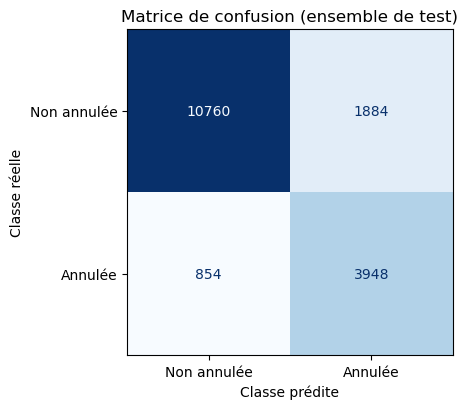

In [7]:
vn, fp, fn, vp = confusion_matrix(y_test, y_pred).ravel()
print("Vrais négatifs (non annulée, bien prédite) :", vn)
print("Faux positifs (non annulée, prédite annulée) :", fp)
print("Faux négatifs (annulée, prédite non annulée) :", fn)
print("Vrais positifs (annulée, bien prédite) :", vp)

fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Non annulée", "Annulée"],
    cmap="Blues", colorbar=False, values_format="d", ax=ax,
)
ax.set_title("Matrice de confusion (ensemble de test)")
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
plt.tight_layout()
plt.savefig(DOSSIER_FIGURES / "05_matrice_confusion.png", dpi=120)
plt.show()

**Ce qu'on observe :**

- Sur les 4 802 annulations du test :
    - 3 948 sont bien trouvées ;
    - 854 sont manquées (le modèle dit « non annulée »).
- Sur les 12 644 réservations non annulées :
    - 10 760 sont bien prédites ;
    - 1 884 sont des fausses alertes (le modèle dit « annulée »).
- Pour l'hôtel, une annulation manquée peut laisser une chambre vide. Une fausse alerte coûte moins cher, par exemple un simple rappel au client. C'est pour ça qu'on a choisi un modèle qui favorise le rappel avec `class_weight="balanced"`.

In [8]:
# Surapprentissage : on compare le score sur le train et sur le test
f1_train = f1_score(y_train, pipeline_final.predict(X_train))
print("F1 sur le train :", round(f1_train, 3))
print("F1 sur le test :", round(f1_score(y_test, y_pred), 3))

F1 sur le train : 0.904
F1 sur le test : 0.743


**Ce qu'on observe :**

- Le F1 est de 0,904 sur le train et de 0,743 sur le test.
- L'écart montre un certain surapprentissage : le modèle connaît mieux les réservations qu'il a déjà vues.
- Le score sur le test reste quand même bon et proche de la validation croisée (0,727). Le modèle généralise correctement.
- Piste d'amélioration : limiter la profondeur des arbres ou chercher de meilleurs réglages avec `GridSearchCV`.

In [9]:
# Exemples de prédictions sur 8 réservations du test
colonnes_exemple = ["hotel", "lead_time", "deposit_type", "country", "total_of_special_requests"]
exemples = X_test.head(8)[colonnes_exemple].copy()
exemples["reel"] = y_test.head(8).values
exemples["predit"] = y_pred[:8]
exemples["proba_annulation_%"] = (y_proba[:8] * 100).round(1)
exemples

,hotel,lead_time,deposit_type,country,total_of_special_requests,reel,predit,proba_annulation_%
0,City Hotel,21,No Deposit,DEU,2,0,0,42.8
1,City Hotel,30,No Deposit,CZE,0,1,1,80.8
2,City Hotel,0,No Deposit,PRT,0,0,0,6.3
3,Resort Hotel,27,No Deposit,ITA,1,0,0,1.7
4,City Hotel,186,No Deposit,DEU,0,0,0,0.7
5,Resort Hotel,4,No Deposit,PRT,0,0,0,27.2
6,City Hotel,6,No Deposit,BGD,0,1,1,63.9
7,City Hotel,79,No Deposit,ESP,1,0,0,4.5


**Ce qu'on observe :**

- Le modèle a raison pour les 8 réservations.
- Il donne aussi une probabilité d'annulation. Exemples :
    - ligne 1 : 80,8 %, et la réservation est bien annulée ;
    - ligne 4 : 0,7 %, et la réservation n'est pas annulée.
- La ligne 0 est un cas moins sûr (42,8 %) : le modèle prédit « non annulée », mais de peu, car le seuil de décision est 50 %.
- Avec ces probabilités, l'hôtel pourrait contacter en priorité les réservations les plus à risque.

## Bilan du projet

- **Pipeline complet** en 3 grandes étapes :
    - prétraitement, avec nos 2 transformateurs personnalisés ;
    - sélection des caractéristiques (54 colonnes sur 108) ;
    - forêt aléatoire.
- **Résultats sur le test :** F1 de 0,743, rappel de 0,822 et ROC AUC de 0,918.
- **Variables les plus utiles :**
    - le délai de réservation ;
    - le pays (Portugal) ;
    - les demandes spéciales ;
    - la place de stationnement.
- **Décisions importantes sur les données :**
    - suppression des doublons, pour ne pas avoir les mêmes lignes dans le train et le test ;
    - retrait de 3 colonnes avec fuite de données.
- **Limites :**
    - les données couvrent seulement 2015 à 2017 et deux hôtels au Portugal ; il faudrait tester le modèle sur des données plus récentes ;
    - le modèle a un certain surapprentissage (F1 de 0,904 sur le train).
- **Pistes d'amélioration :**
    - chercher de meilleurs réglages avec `GridSearchCV` ;
    - changer le seuil de décision (50 % par défaut) selon ce que coûte une annulation manquée pour l'hôtel.